In [1]:
import sys
import pystac_client
import planetary_computer
import matplotlib.pyplot as plt

import numpy as np
import xarray as xr 
from scipy.ndimage import uniform_filter


import datacube
import odc.stac
from odc.geo.geom import BoundingBox

sys.path.insert(1, "../Tools/")
from dea_tools.datahandling import load_ard
from dea_tools.plotting import display_map

In [2]:
# -28.79433,153.25317

# -28.78212,153.23947
# -28.84756,153.35528

x = (153.23947, 153.30528)
y = (-28.84756, -28.78212)
time = ("2017-03", "2017-04")

In [3]:
display_map(x=x, y=y)

*Load data from Planetary Computer*

In [4]:
# Open a client pointing to the Microsoft Planetary Computer data catalogue
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

In [5]:
# Convert data-cube style queries into something readable by `pystac_client`
bbox = BoundingBox.from_xy(x, y)
time_range = "/".join(time)

# Search for STAC items from "sentinel-1-rtc" product
# sentinel-1-grd
search = catalog.search(
    collections="sentinel-1-rtc",
    bbox=bbox,
    datetime=time_range,
)

# Check how many items were returned
items = search.item_collection()
print(f"Found {len(items)} STAC items")

Found 10 STAC items


In [6]:
# Load ESA WorldCover data with odc-stac
rtc = odc.stac.load(
    items,
    bbox=bbox,
    bands=["vv", "vh"],
    crs="EPSG:3577",
    resolution=30,
)

In [7]:
rtc

<xarray.Dataset> Size: 6MB
Dimensions:      (y: 277, x: 251, time: 10)
Coordinates:
  * y            (y) float64 2kB -3.297e+06 -3.297e+06 ... -3.305e+06 -3.305e+06
  * x            (x) float64 2kB 2.038e+06 2.038e+06 ... 2.046e+06 2.046e+06
    spatial_ref  int32 4B 3577
  * time         (time) datetime64[ns] 80B 2017-03-04T19:05:52.246503 ... 201...
Data variables:
    vv           (time, y, x) float32 3MB 0.2064 0.06923 ... 0.06497 0.2511
    vh           (time, y, x) float32 3MB 0.0385 0.02222 ... 0.03701 0.04869

In [8]:
def dB_scale(data): 
    '''Scales a xarray.DataArray with linear DN to a dB scale.'''
    # Explicitly set negative data to nan to avoid log of negative number
    negative_free_data = data.where(data >= 0, np.nan)
    return 10 * np.log10(negative_free_data)

# Visualise RTC samples

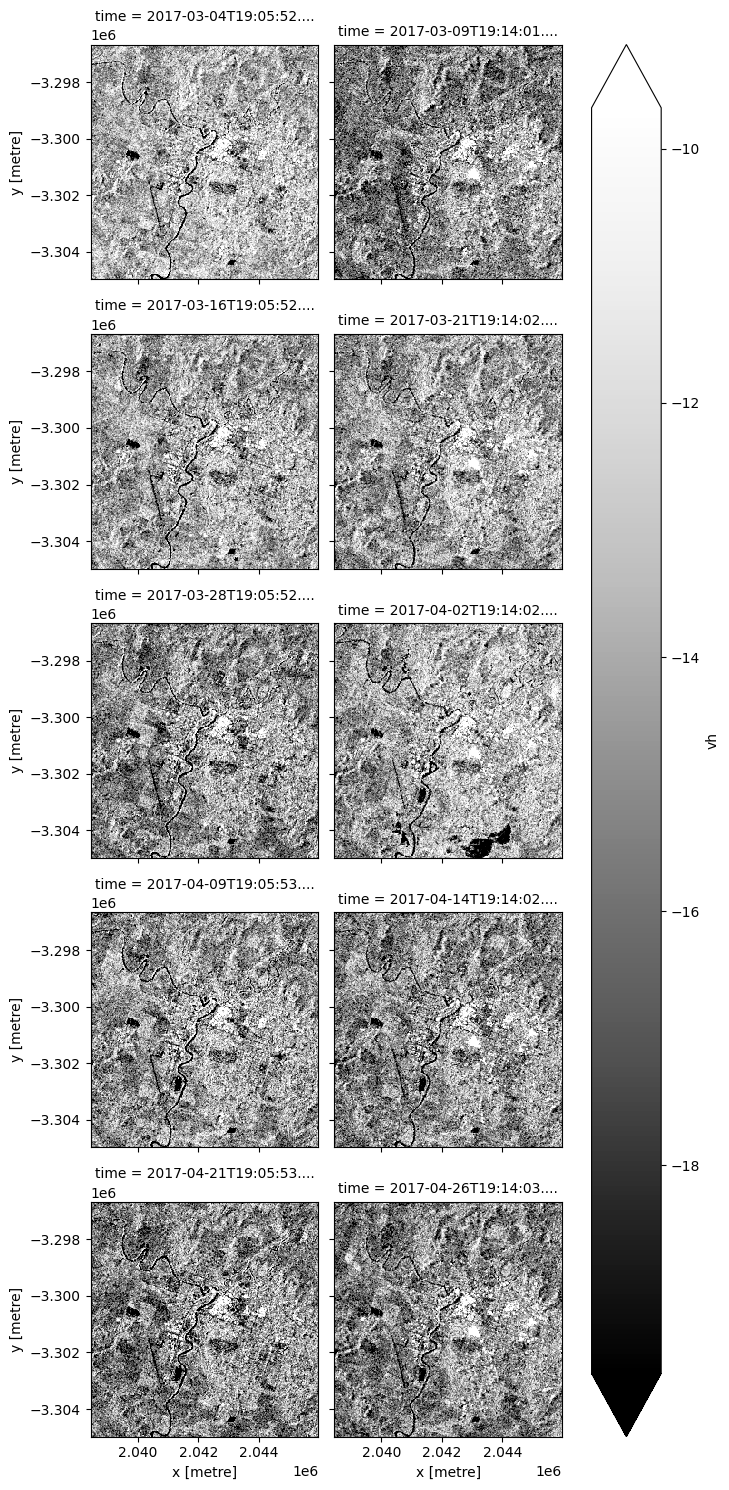

In [9]:
# Scale to plot data in decibels
rtc_db = {"vh": dB_scale(rtc.vh), "vv": dB_scale(rtc.vv)}

# Plot all VH observations for the year
rtc_db["vh"].plot(cmap="Greys_r", robust=True, col="time", col_wrap=2)
plt.show()

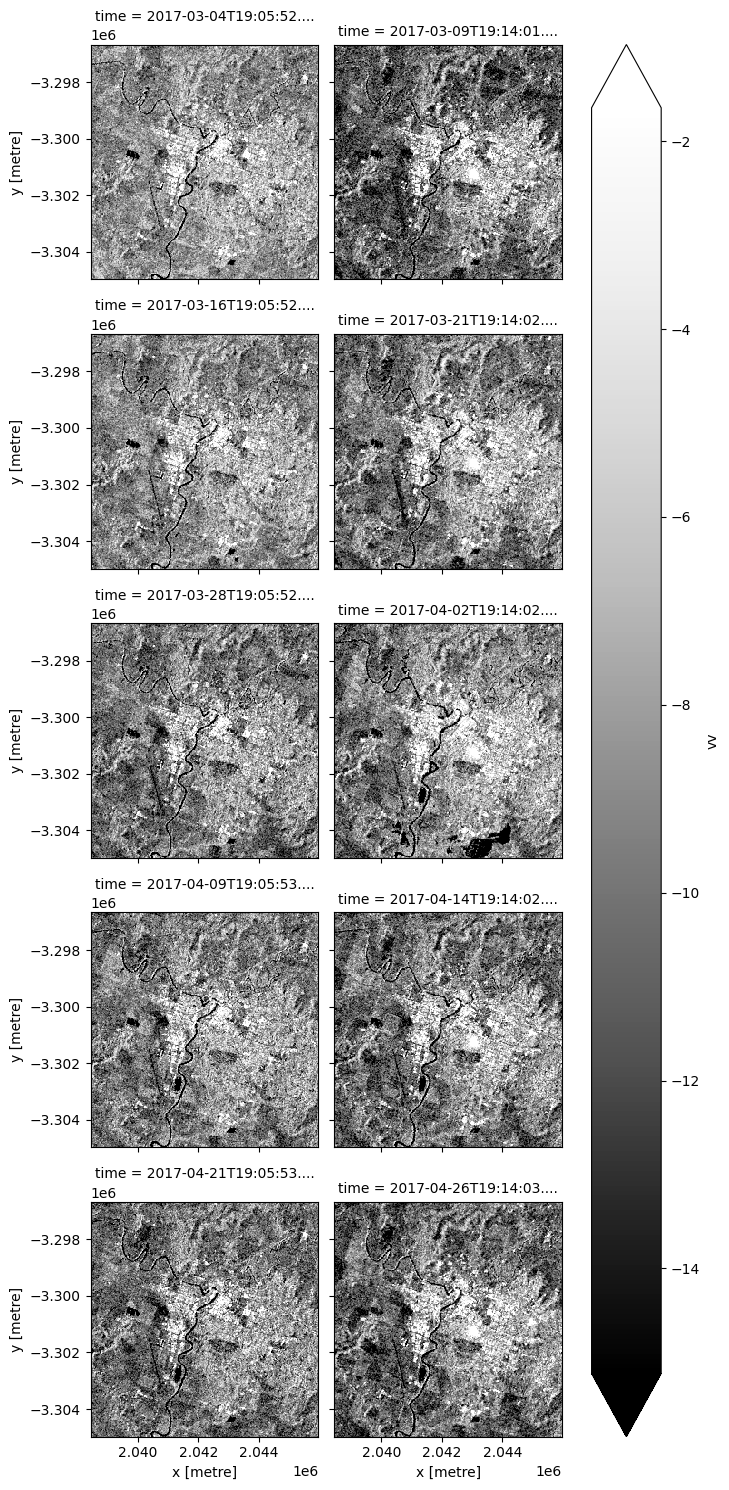

In [10]:
# Scale to plot data in decibels
# Plot all VH observations for the year
rtc_db["vv"].plot(cmap="Greys_r", robust=True, col="time", col_wrap=2)
plt.show()

## Apply Lee speckle filter

In [11]:
# Code from Radar_water_detection.ipynb
# Adapted from https://stackoverflow.com/questions/39785970/speckle-lee-filter-in-python
def lee_filter(img, size):
    """
    Applies the Lee filter to reduce speckle noise in an image.

    Parameters:
    img (ndarray): Input image to be filtered.
    size (int): Size of the uniform filter window.

    Returns:
    ndarray: The filtered image.
    """
    img_mean = uniform_filter(img, size)
    img_sqr_mean = uniform_filter(img**2, size)
    img_variance = img_sqr_mean - img_mean**2

    overall_variance = np.var(img)

    img_weights = img_variance / (img_variance + overall_variance)
    img_output = img_mean + img_weights * (img - img_mean)
    return img_output

# Define a function to apply the Lee filter to a DataArray
def apply_lee_filter(data_array, size=7):
    """
    Applies the Lee filter to the provided DataArray.

    Parameters:
    data_array (xarray.DataArray): The data array to be filtered.
    size (int): Size of the uniform filter window. Default is 7.

    Returns:
    xarray.DataArray: The filtered data array.
    """
    data_array_filled = data_array.fillna(0)
    filtered_data = xr.apply_ufunc(
        lee_filter, data_array_filled,
        kwargs={"size": size},
        input_core_dims=[["y", "x"]],
        output_core_dims=[["y", "x"]],
        dask_gufunc_kwargs={"allow_rechunk": True},
        vectorize=True,
        dask="parallelized",
        output_dtypes=[data_array.dtype]
    )
    return filtered_data

In [12]:
# Apply the Lee filter to both VV and VH data
rtc["filtered_vv"] = apply_lee_filter(rtc['vv'], size = 7)
rtc["filtered_vh"] = apply_lee_filter(rtc['vh'], size = 7)


rtc_db["filtered_vv"] = dB_scale(rtc["filtered_vv"])
rtc_db["filtered_vh"] = dB_scale(rtc["filtered_vh"])

In [13]:
# Balanced Histogram Thresholding, helper function used in both approaches
# From GEOM7004, where it seemingly came from Wikipedia (!)

def balanced_histogram_thresholding(histogram, minimum_bin_count: int = 5, jump: int = 1) -> int:
    # Find the start and end indices where the histogram bins are significant
    start_index = 0
    while start_index < len(histogram) and histogram[start_index] < minimum_bin_count:
        start_index += 1
    
    end_index = len(histogram) - 1
    while end_index >= 0 and histogram[end_index] < minimum_bin_count:
        end_index -= 1

    # Check if no valid bins are found
    if start_index >= end_index:
        return -1  # Indicates an error or non-applicability

    # Initialize threshold
    threshold = (start_index + end_index) // 2

    # Iteratively adjust the threshold
    while start_index <= end_index:
        # Calculate weights on both sides of the threshold
        weight_left = sum(histogram[start_index:threshold])
        weight_right = sum(histogram[threshold:end_index + 1])

        # Adjust the threshold based on the weights
        if weight_left > weight_right:
            start_index += jump
        elif weight_left < weight_right:
            end_index -= jump
        else:  # Equal weights; move both indices
            start_index += jump
            end_index -= jump

        # print(f"weights: {weight_left} | {weight_right} indx: {start_index} | {end_index}")
        
        # Calculate the new threshold
        threshold = (start_index + end_index) // 2

    return threshold

## Approach A - Classify then change-detect

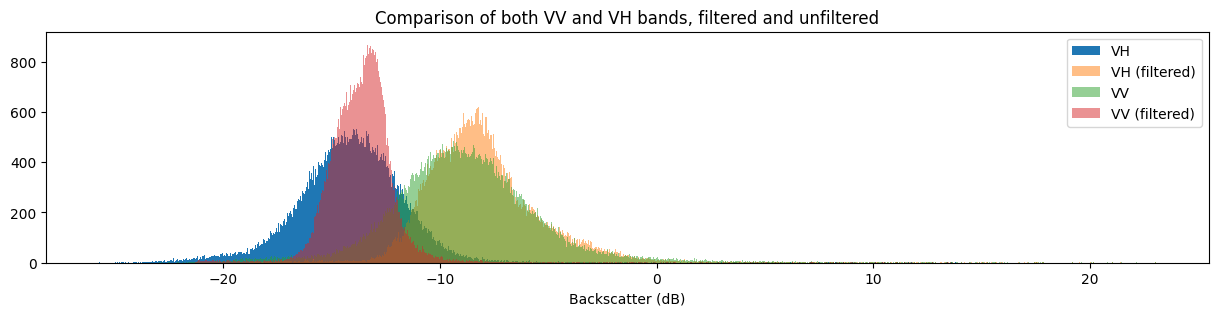

In [14]:
figt = plt.figure(figsize=(15, 3))
rtc_db["vh"].sel(time='2017-04-02').plot.hist(bins=1000, label="VH")
rtc_db["filtered_vv"].sel(time='2017-04-02').plot.hist(bins=1000, alpha=0.5, label="VH (filtered)")
rtc_db["vv"].sel(time='2017-04-02').plot.hist(bins=1000, alpha=0.5, label="VV")
rtc_db["filtered_vh"].sel(time='2017-04-02').plot.hist(bins=1000, alpha=0.5, label="VV (filtered)")
plt.legend()
plt.xlabel("Backscatter (dB)")
plt.title("Comparison of both VV and VH bands, filtered and unfiltered")
plt.show()

# Could apply BHT, but this would not help much...!
# TODO: Add legends

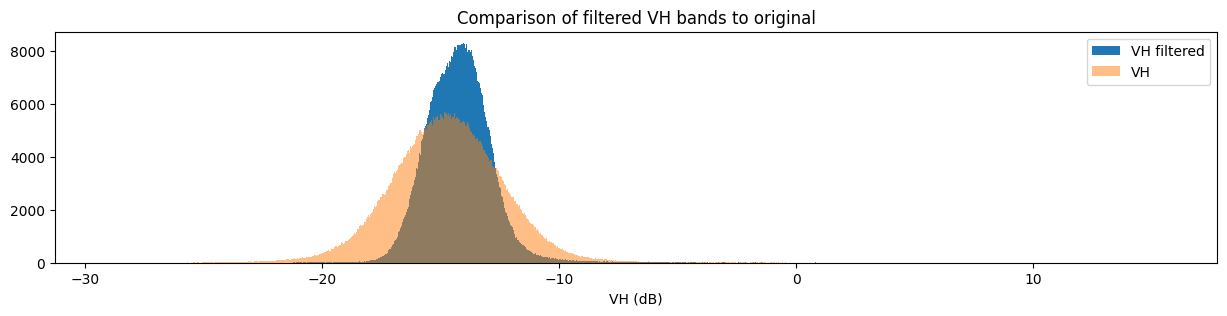

In [15]:
fig = plt.figure(figsize=(15, 3))
rtc_db["filtered_vh"].plot.hist(bins=1000, label="VH filtered")
rtc_db["vh"].plot.hist(bins=1000, label="VH", alpha=0.5)
plt.legend()
plt.xlabel("VH (dB)")
plt.title("Comparison of filtered VH bands to original")
plt.show()

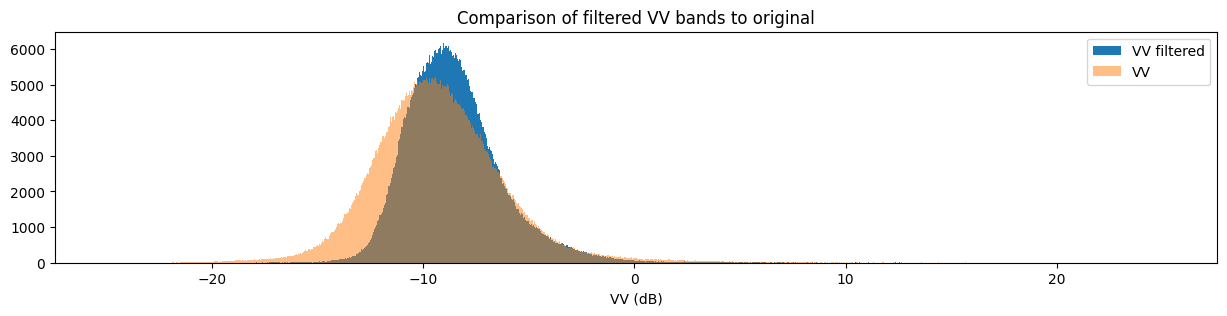

In [16]:
fig = plt.figure(figsize=(15, 3))
rtc_db["filtered_vv"].plot.hist(bins=1000, label="VV filtered")
rtc_db["vv"].plot.hist(bins=1000, label="VV", alpha=0.5)
plt.legend()
plt.xlabel("VV (dB)")
plt.title("Comparison of filtered VV bands to original")
plt.show()

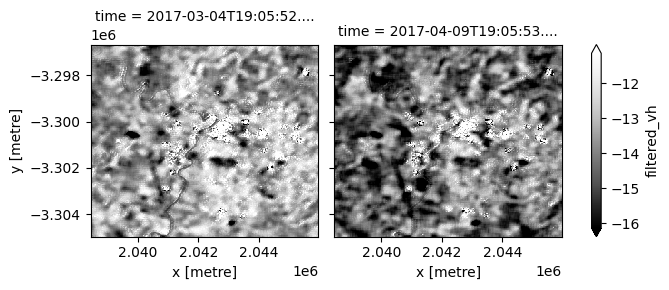

In [17]:
a_frames = rtc_db["filtered_vh"].isel(time=[0,6])
a_frames.plot(cmap="Greys_r", robust=True, col="time")

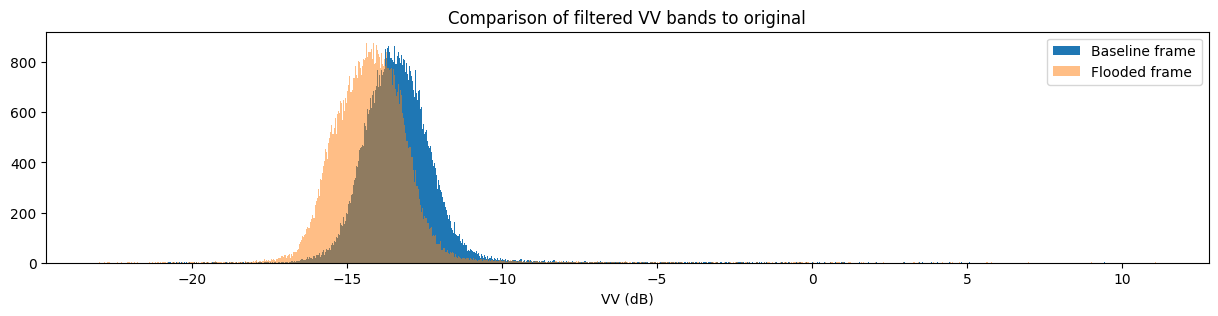

In [18]:
fig = plt.figure(figsize=(15, 3))
a_frames.isel(time=[0]).plot.hist(bins=1000, label="Baseline frame")
a_frames.isel(time=[1]).plot.hist(bins=1000, label="Flooded frame", alpha=0.5)
plt.legend()
plt.xlabel("VV (dB)")
plt.title("Comparison of filtered VV bands to original")
plt.show()

In [19]:
# In line with the original approach, we will use the VH band

a_hists_vh = np.histogram(a_frames, bins=100)
a_thrshld = balanced_histogram_thresholding(a_hists_vh[0], minimum_bin_count = 500)
print(a_thrshld, "->", a_hists_vh[1][a_thrshld])

19 -> -16.531023


In [20]:
a_water = (a_frames > a_hists_vh[1][a_thrshld]).astype(int)

In [53]:
a_water.rio.to_raster("a_output.tif")

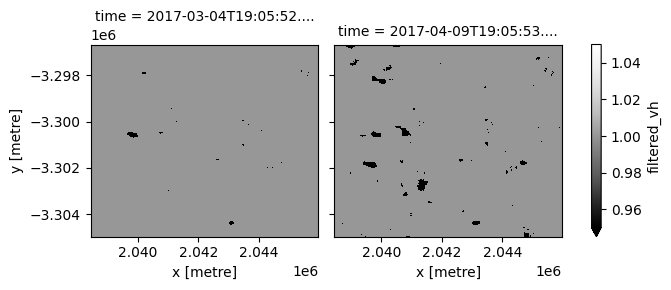

In [21]:
a_water.plot(cmap="Greys_r", robust=True, col="time", col_wrap=2)

## Approach B - Change detection on data

In [22]:
#baseline_index = 0

# From https://www.esri.com/arcgis-blog/products/arcgis-pro/imagery/extracting-water-from-sar-satellite-data
#  (0.1747 · dBvv) + (0.0082 · dBvh · dBvv) + (0.0023 · dBvv2) – (0.0015 · dBvh2) + 0.1904

#index = (0.1747 * rtc_db["filtered_vv"]) + (0.0092 * rtc_db["filtered_vh"] * rtc_db["filtered_vv"]) + (0.0023 * rtc_db["filtered_vv"] ** 2) - (0.0015 * rtc_db["filtered_vh"] ** 2) + 0.1904
b_frames = rtc_db["filtered_vv"].isel(time=[0,6])

nci = (b_frames.isel(time=[1])[0] - b_frames.isel(time=[0])[0])/(b_frames.isel(time=[1])[0] + b_frames.isel(time=[0])[0])

In [23]:
nci

<xarray.DataArray 'filtered_vv' (y: 277, x: 251)> Size: 278kB
array([[ 0.10083647,  0.09813623,  0.10308076, ...,  0.00660063,
        -0.02146838,  0.0112011 ],
       [ 0.09853177,  0.0951797 ,  0.10239875, ..., -0.01507803,
        -0.04026895, -0.0117862 ],
       [ 0.08871583,  0.09124197,  0.10252451, ..., -0.02277955,
        -0.0461197 , -0.02341238],
       ...,
       [ 0.00163218,  0.02650676,  0.05221362, ...,  0.04895864,
         0.02416742,  0.01405272],
       [ 0.00515898,  0.0303295 ,  0.04929457, ...,  0.05612504,
         0.0311196 ,  0.01318028],
       [ 0.0239288 ,  0.04822045,  0.061129  , ...,  0.04721092,
         0.01316171, -0.01828583]], shape=(277, 251), dtype=float32)
Coordinates:
  * y            (y) float64 2kB -3.297e+06 -3.297e+06 ... -3.305e+06 -3.305e+06
  * x            (x) float64 2kB 2.038e+06 2.038e+06 ... 2.046e+06 2.046e+06
    spatial_ref  int32 4B 3577

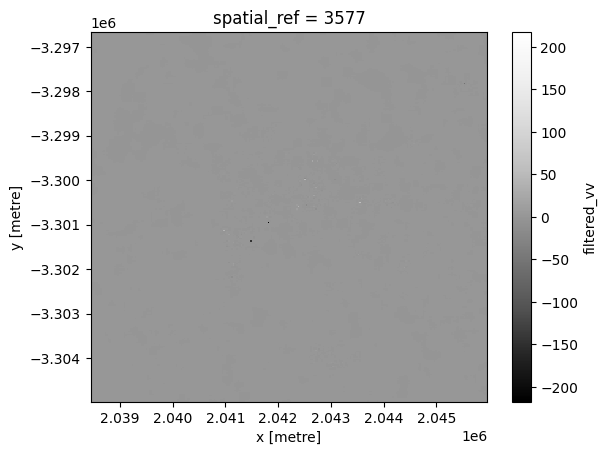

In [24]:
nci.plot(cmap="Greys_r")

In [55]:
nci.rio.to_raster("b_output.tif")

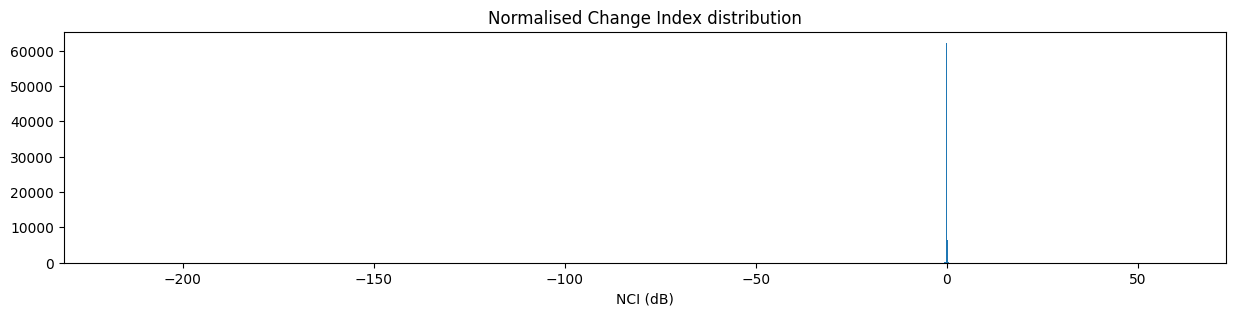

In [25]:
fig = plt.figure(figsize=(15, 3))
nci.plot.hist(bins=1000)
# plt.legend()
plt.xlabel("NCI (dB)")
plt.title("Normalised Change Index distribution")
plt.show()

## Validation
### Bathtub model reference


In [44]:
# Retrieve 250m topo

# multi_scale_topographic_position, ga_ausbathytopo250m_2023, ga_multi_ausbath_0

dc = datacube.Datacube(app="validation")

search_topo = catalog.search(
    collections="ga_multi_ausbath_0",
    bbox=bbox,
)

query = {
    "x": x,
    "y": y,
    "product": "ga_multi_ausbath_0",
    "output_crs": "EPSG:4326",
    "resolution": (0.0001356, 0.0001356)
}

dss = dc.find_datasets(**query)

topo = dc.load(datasets=dss,**query)

In [45]:
topo

<xarray.Dataset> Size: 478kB
Dimensions:       (time: 1, latitude: 484, longitude: 486)
Coordinates:
  * time          (time) datetime64[ns] 8B 2016-03-17T13:22:22.263375
  * latitude      (latitude) float64 4kB -28.85 -28.85 -28.85 ... -28.78 -28.78
  * longitude     (longitude) float64 4kB 153.2 153.2 153.2 ... 153.3 153.3
    spatial_ref   int32 4B 4326
Data variables:
    height_depth  (time, latitude, longitude) int16 470kB 55 55 55 ... 17 17 16
Attributes:
    crs:           EPSG:4326
    grid_mapping:  spatial_ref

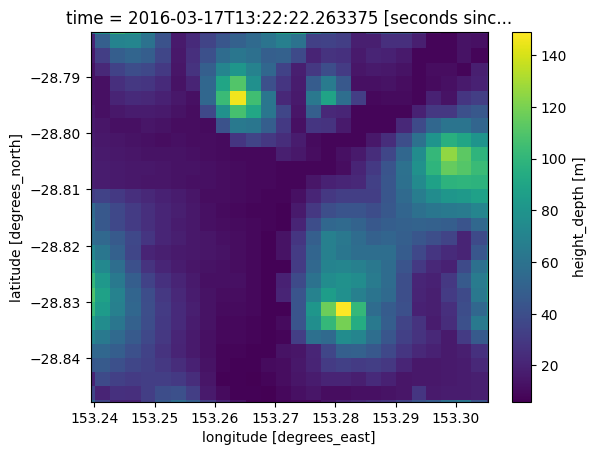

In [46]:
topo.height_depth.plot()

In [51]:
topo.height_depth.rio.to_raster('topology.tif')

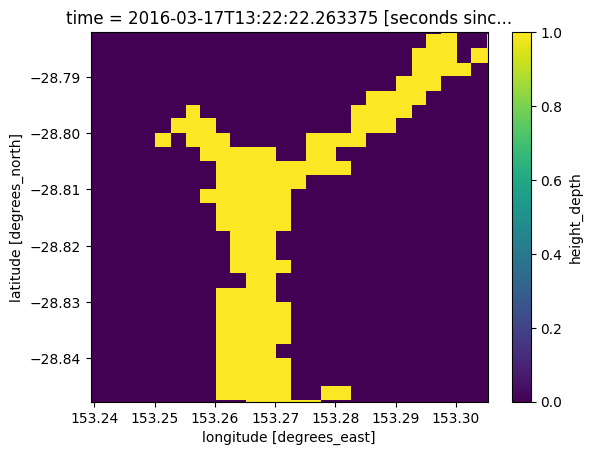

In [48]:
(topo.height_depth < 11.6).plot()